# GSTRIDE - Exploratory Analysis

**Gait-derived endurance from a single sustained walk in older adults**

**Operational definition.** Gait-derived endurance = the within-walk decline in
spatiotemporal gait parameters (speed, stride length, cadence) across a continuous
walk of roughly 20 minutes recorded by a foot-mounted IMU (after García et al.).

**Target population.** Community-dwelling and institutionalised older adults, where
falls are common and clinic-based screening has to be brief.

---
## 0. Setup

Plot styling follows a validated categorical palette, with two load-bearing rules
respected throughout:

- **Scatter-type forms** (where any two colours can land side by side) use at most
  the **first three slots** — that subset is validated for all pairwise comparisons
  under colour-vision deficiency.
- **Ordered categories** (e.g. frailty 0–4) use a **single-hue blue ordinal ramp**
  starting no lighter than step 250, so the lightest mark still separates from the
  surface. Never a rainbow for an ordered quantity.

In [1]:
import os, re, glob, shlex, warnings, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# ---------------------------------------------------------------- paths
ROOT = Path("GSTRIDE_database")
assert ROOT.is_dir(), f"GSTRIDE_database not found next to this notebook (cwd={Path.cwd()})"

REGISTER    = ROOT / "Database_register.csv"
DIR_METRICS = ROOT / "Test_outputs_gait_analysis"        # per-stride gait parameters
DIR_CALIB   = ROOT / "Test_recordings_calibrated"        # calibrated IMU time series
DIR_RAW     = ROOT / "Test_recordings_raw"               # raw ADC counts
DIR_CALPAR  = ROOT / "Test_sensors_calibration_parameters"
DERIVED = Path("derived"); DERIVED.mkdir(exist_ok=True)

# ---------------------------------------------------------------- palette
INK, INK_2 = "#0b0b0b", "#52514e"      # primary / secondary text
GRID, SURFACE = "#e3e2de", "#fcfcfb"

# categorical slots in fixed order - never cycled, never reordered by rank
CAT   = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
         "#008300", "#4a3aa7", "#e34948"]
SAFE3 = CAT[:3]                        # the all-pairs-validated subset

# single-hue ordinal ramp (blue, steps 250 -> 650) for ORDERED categories
ORDINAL  = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
SEQ_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#184f95", "#0d366b"])
# diverging: opposing poles with a NEUTRAL GRAY midpoint (never a hue at zero)
DIV_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "div_br", ["#104281", "#2a78d6", "#9ec5f4", "#f0efec", "#f3a3a2", "#e34948", "#a62625"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE,  "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "font.size": 9.5,
    "axes.titlesize": 11, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelsize": 9.5, "axes.labelcolor": INK_2,
    "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 8.5,
    "lines.linewidth": 2.0, "lines.markersize": 5,
    "figure.constrained_layout.use": True,
})

def finish(ax, title=None, sub=None, xlab=None, ylab=None):
    # Titles/labels wear text tokens, never a series colour.
    if title: ax.set_title(title, color=INK)
    if sub:   ax.text(0, 1.012, sub, transform=ax.transAxes, color=INK_2,
                      fontsize=8.5, va="bottom")
    if xlab is not None: ax.set_xlabel(xlab)
    if ylab is not None: ax.set_ylabel(ylab)
    return ax

def barlabel(ax, bars, fmt="{:.0f}", pad=2, horiz=False):
    # Selective direct labels on bars; keeps identity off colour alone.
    for b in bars:
        if horiz:
            w = b.get_width()
            ax.text(w + pad, b.get_y() + b.get_height()/2, fmt.format(w),
                    va="center", ha="left", fontsize=8, color=INK_2)
        else:
            h = b.get_height()
            ax.text(b.get_x() + b.get_width()/2, h + pad, fmt.format(h),
                    ha="center", va="bottom", fontsize=8, color=INK_2)

print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", mpl.__version__)
print("root :", ROOT.resolve())

numpy 2.2.6 | pandas 2.3.3 | matplotlib 3.10.9
root : /home/ahmed.osman2/BMEN600/GSTRIDE_database


---
## 1. Dataset provenance and file structure

**GSTRIDE** is an open database of foot-mounted inertial recordings from older adults,
published with a Python reference pipeline. Each volunteer (`V001`…`V163`) contributes
one sustained walk plus a battery of clinical tests.

The sensor sits **on the foot**, which is what makes per-stride *spatial* parameters
recoverable: the foot is briefly stationary during flat-foot contact, so a
zero-velocity update (ZUPT) can reset inertial drift once per stride. The reference
pipeline is Mahony AHRS for orientation → pitch-based step and phase detection →
ZUPT-corrected strapdown integration for stride length and clearance.

Two devices were used, **at different sampling rates**, heterogeneity to carry
through the whole analysis:

| Device | Sampling rate | Raw units |
|---|---|---|
| `CSIC` (ad-hoc) | 104 Hz | ADC counts |
| `Gaitup` Physilog P6S (id `0185`) | 128 Hz | pre-scaled a.u. |

In [2]:
def dir_summary(d):
    files = sorted(p for p in d.iterdir() if p.is_file())
    return dict(directory=d.name, n_files=len(files),
                size_MB=round(sum(p.stat().st_size for p in files) / 1e6, 1),
                example=files[0].name if files else "")

layout = pd.DataFrame([dir_summary(d) for d in sorted(ROOT.iterdir()) if d.is_dir()])
layout["role"] = layout["directory"].map({
    "Test_outputs_gait_analysis":          "per-stride gait parameters  <-- ANALYSIS INPUT",
    "Test_recordings_calibrated":          "calibrated IMU series (m/s^2, rad/s)",
    "Test_recordings_raw":                 "raw IMU in device units; filename carries device id",
    "Test_sensors_calibration_parameters": "per-device calibration constants",
    "Gait_analysis_w_Python":              "authors' reference pipeline",
    "Sensor_specifications":               "sensor datasheets (PDF)",
})
print("Top-level files:", [p.name for p in sorted(ROOT.iterdir()) if p.is_file()], "\n")
display(layout.set_index("directory"))

print("\nReference pipeline modules:")
for p in sorted((ROOT / "Gait_analysis_w_Python").glob("*.py")):
    print("  ", p.name)

# the sampling rate is hard-coded in the authors' driver - confirm rather than assume
drv = (ROOT / "Gait_analysis_w_Python" / "main.py").read_text()
hits = [l.strip() for l in drv.splitlines() if re.search(r"\bfs\s*=\s*\d+|Nbeacon ==", l)]
print("\nSampling-rate logic in main.py:")
print(textwrap.indent("\n".join(hits), "   "))

Top-level files: ['Database_register.csv', 'Database_register.xlsx'] 



,n_files,size_MB,example,role
directory,,,,
Gait_analysis_w_Python,7,0.000,Gait_Parameters_Estimation.py,authors' reference pipeline
Sensor_specifications,2,2.000,Specifications-CSIC_adhoc.pdf,sensor datasheets (PDF)
Test_outputs_gait_analysis,163,13.600,V001_metrics.txt,per-stride gait parameters <-- ANALYSIS INPUT
Test_recordings_calibrated,158,"2,693.900",V001.txt,"calibrated IMU series (m/s^2, rad/s)"
Test_recordings_raw,158,773.200,V001_45C9.txt,raw IMU in device units; filename carries devi...
Test_sensors_calibration_parameters,12,0.000,C185.txt,per-device calibration constants



Reference pipeline modules:
   Gait_Parameters_Estimation.py
   INS_ZUPT.py
   MahonyAHRS.py
   StepDetection_MultiCorrector_Pitch.py
   main.py
   readLogFileArduinoCalib.py

Sampling-rate logic in main.py:
   if Nbeacon == '0185':
   fs = 128
   fs = 104


### 1.1 Subject coverage across directories

Not every volunteer has every file type. The register's `Notes` column documents the
gap; the check below confirms it rather than trusting it.

In [3]:
ids_metrics = {p.name.split("_")[0] for p in DIR_METRICS.glob("*_metrics.txt")}
ids_calib   = {p.stem for p in DIR_CALIB.glob("V*.txt")}
ids_raw     = {p.name.split("_")[0] for p in DIR_RAW.glob("V*.txt")}

display(pd.DataFrame({"per-stride metrics": [len(ids_metrics)],
                      "calibrated IMU":     [len(ids_calib)],
                      "raw IMU":            [len(ids_raw)]}, index=["n subjects"]))

no_signal = sorted(ids_metrics - ids_calib)
print(f"Metrics but NO raw/calibrated signal ({len(no_signal)}): {no_signal}")
print(f"Signal but no metrics: {sorted(ids_calib - ids_metrics) or 'none'}")

dev_from_file = pd.Series({p.name.split("_")[0]: p.name.split("_")[1].split(".")[0]
                           for p in DIR_RAW.glob("V*.txt")}).sort_index()
print(f"\nDistinct device ids in raw filenames: {sorted(dev_from_file.unique())}")
print(f"Calibration-parameter files:          {sorted(p.stem for p in DIR_CALPAR.glob('*.txt'))}")

,per-stride metrics,calibrated IMU,raw IMU
n subjects,163,158,158


Metrics but NO raw/calibrated signal (5): ['V142', 'V143', 'V157', 'V158', 'V159']
Signal but no metrics: none

Distinct device ids in raw filenames: ['0185', '0877', '45C9', '4C86', '61CE', '63CA', '66CC', 'AD09', 'E59B', 'EBE4', 'F98D']
Calibration-parameter files:          ['C185', 'C332E', 'C45C9', 'C4C86', 'C61CE', 'C63CA', 'C66CC', 'C877', 'CAD09', 'CE59B', 'CEBE4', 'CF98D']


> **Implication.** Those five subjects still have per-stride metrics. Because this
> study works from **per-stride parameters** rather than raw signal, they stay in the
> analysis — but they cannot be re-processed if we later want different step-detection
> settings. Any plan to re-derive gait parameters from scratch is capped at n = 158.

---
## 2. Loading the clinical register

In [4]:
print("--- first three physical rows of the register ---")
with open(REGISTER, encoding="latin-1") as f:
    for i in range(3):
        line = f.readline().rstrip("\n")
        print(f"[row {i}] {line[:200]}{' ...' if len(line) > 200 else ''}\n")

--- first three physical rows of the register ---
[row 0] ;Test data;;;;;;;;;;;Anatomical, functional and cognitive variables;;;;Gait test of 4-meter walk;;Frailty critieria;;;;;;;Short Physical Performance Battery (SPPB) test;;;;Timed up and go (TUG) test;S ...

[row 1] Test index;ID (VNNN);Notes;Date (Month-YY);Falls during the last year - prior to test (YES/NO);Type of device (CSIC/Gaitup);Device Id. (identifier);Location (Consultation, Nursing home, Familiar);Test ...

[row 2] ;Volunteer index;Specific considerations of volunteers;;"YES: they fell during the last year; NO: otherwise";"CSIC: ad-hoc made; Gaitup: from gaitup commertial brand";;;"Plane: inside of bulidings; Va ...



In [5]:
raw_reg = pd.read_csv(REGISTER, sep=";", header=1, skiprows=[2],
                      decimal=",", encoding="latin-1")
print("shape:", raw_reg.shape)

# which columns LOOK numeric but arrived as object, and what is blocking them
print("\nObject columns that are really numeric, and the sentinels in them:")
for c in raw_reg.columns[raw_reg.dtypes == object]:
    v = raw_reg[c].dropna().astype(str).str.strip()
    bad = v[~v.str.fullmatch(r"-?\d+(?:[.,]\d+)?")]
    if 0 < len(bad) < len(v):                 # mostly numeric => a real number column
        print(f"  {c!r:54s} {bad.value_counts().to_dict()}")

print("\nCategorical columns carrying whitespace variants:")
for c in raw_reg.columns[raw_reg.dtypes == object]:
    v = raw_reg[c].dropna().astype(str)
    if (v != v.str.strip()).any():
        print(f"  {c!r:54s} {v.value_counts().to_dict()}")

print("\nNotes column (explains the coverage gap above):")
display(raw_reg.loc[raw_reg["Notes"].notna(), ["ID (VNNN)", "Notes"]])

shape: (163, 60)

Object columns that are really numeric, and the sentinels in them:
  'Device Id. (identifier)'                              {'45C9': 27, 'E59B': 25, '61CE': 18, 'AD09': 15, '63CA': 14, 'F98D': 13, '66CC': 12, '4C86': 12, 'EBE4': 7}
  'Manual force  (kg)'                                   {'-': 2, 'Incapable': 1}
  'Balance test (index)'                                 {'Incapable': 1}
  'Chair stand test (index)'                             {'Incapable': 1}
  'Time duration TUG test (s)'                           {'Incapable': 15, '-': 1}
  'Short FES-I assessment (index)'                       {'Incapable': 16, '-': 2}

Categorical columns carrying whitespace variants:
  'Falls during the last year - prior to test (YES/NO)'  {'YES': 86, 'NO': 69, 'NO ': 8}

Notes column (explains the coverage gap above):


,ID (VNNN),Notes
139,V140,Deaf
141,V142,No raw data
142,V143,No raw data
156,V157,No raw data
157,V158,No raw data
158,V159,No raw data


In [6]:
SENTINELS = {"Incapable", "-", "", "nan", "NaN"}

def to_num(s):
    # Coerce a sentinel-laden object column to float.
    t = s.astype(str).str.strip().str.replace(",", ".", regex=False)
    return pd.to_numeric(t.where(~t.isin(SENTINELS)), errors="coerce")

def yes_no(s):
    # YES/NO -> 1/0, whitespace tolerant; anything else (e.g. 'Incapable') -> NaN.
    return s.astype(str).str.strip().str.upper().map({"YES": 1.0, "NO": 0.0})

RENAME = {
    "ID (VNNN)": "id", "Notes": "notes", "Date (Month-YY)": "date",
    "Falls during the last year - prior to test (YES/NO)": "falls_1y",
    "Type of device (CSIC/Gaitup)": "device", "Device Id. (identifier)": "device_id",
    "Location (Consultation, Nursing home, Familiar)": "location",
    "Test surface (type of surface)": "surface",
    "Age (range of years)": "age_band", "Sex (M/ F)": "sex",
    "Living in a nursing home (YES/NO)": "nursing_home",
    "Weight (kg)": "weight_kg", "Height (m)": "height_m", "Body-mass index (BMI)": "bmi",
    "Global Deterioration Scale (GDS) questionnaire (index)": "gds",
    "Time duration 4m test (s)": "t_4m_s", "Gait speed (m/s)": "gait_speed_4m",
    "Unintentional weight loss (YES/NO)": "fr_weight_loss",
    "Low energy and resistance (YES/NO)": "fr_low_energy",
    "Gait speed clinical assessment (YES/NO)": "fr_slow_gait",
    "Manual force  (kg)": "grip_kg",
    "Manual force clinical assessment (YES/NO)": "fr_weak_grip",
    "Low activity level (YES/NO)": "fr_low_activity",
    "Frailty assessment (index)": "frailty",
    "Balance test (index)": "sppb_balance", "Gait speed test (index)": "sppb_gait",
    "Chair stand test (index)": "sppb_chair", "SPPB assessment (index)": "sppb",
    "Time duration TUG test (s)": "tug_s",
    "Short FES-I assessment (index)": "fesi",
    "Distance (m)": "walk_distance_m", "Time (s)": "walk_time_s", "Strides": "walk_strides",
}

NUMERIC = ["grip_kg", "sppb_balance", "sppb_chair", "tug_s", "fesi"]
FLAGS   = ["falls_1y", "nursing_home", "fr_weight_loss", "fr_low_energy",
           "fr_slow_gait", "fr_weak_grip", "fr_low_activity"]

# Preserve the 'Incapable' pattern BEFORE coercion destroys it - §4.3 depends on it.
inv = {v: k for k, v in RENAME.items()}
incapable = pd.DataFrame(
    {c: raw_reg[inv[c]].astype(str).str.strip().eq("Incapable") for c in NUMERIC + FLAGS})
incapable.index = pd.Index(raw_reg["ID (VNNN)"].values, name="id")   # relabel, do NOT reindex

reg = raw_reg.rename(columns=RENAME).copy()

# tidy the long-walk summary columns: "Stride Length - Avg. (m)" -> reg_stride_length_avg
def tidy_summary(c):
    m = re.match(r"^(.*?) - (Avg\.|STD) \(.*\)$", c)
    if not m: return c
    base = re.sub(r"[^a-z0-9]+", "_", m.group(1).lower()).strip("_")
    return f"reg_{base}_" + ("avg" if m.group(2).startswith("Avg") else "std")
reg = reg.rename(columns={c: tidy_summary(c) for c in reg.columns})

for c in NUMERIC: reg[c] = to_num(reg[c])
for c in FLAGS:   reg[c] = yes_no(reg[c])
for c in ["device", "location", "surface", "age_band", "sex", "device_id"]:
    reg[c] = reg[c].astype(str).str.strip()
reg["age_mid"] = reg["age_band"].str.extract(r"(\d+)-(\d+)").astype(float).mean(axis=1)
reg = reg.set_index("id")

print(f"register: {reg.shape[0]} subjects x {reg.shape[1]} columns")
print(f"'Incapable' entries kept as a mask: {int(incapable.values.sum())} "
      f"across {int(incapable.any(axis=1).sum())} subjects")
display(reg[["age_band", "sex", "device", "frailty", "sppb", "tug_s",
             "fr_low_energy", "walk_time_s", "walk_strides"]].head())

register: 163 subjects x 60 columns
'Incapable' entries kept as a mask: 45 across 29 subjects


,age_band,sex,device,frailty,sppb,tug_s,fr_low_energy,walk_time_s,walk_strides
id,,,,,,,,,
V001,80-84,F,CSIC,1,11,10.290,0.000,"1,721.270",1688
V002,80-84,M,CSIC,1,9,8.600,0.000,"1,630.180",1278
V003,75-79,F,CSIC,0,9,10.870,0.000,"1,626.640",1202
V004,80-84,M,CSIC,1,9,13.720,0.000,"1,622.440",1273
V005,95-99,M,CSIC,1,5,16.480,1.000,793.250,572


---
## 3. Cohort description

Age is published as **5-year bands**, not exact years — a deliberate de-identification
choice. For any analysis needing a continuous age we use the band midpoint and treat
it as ordinal, never as a precise value.

In [7]:
n = len(reg)

def pct(k):   return f"{k} ({100*k/n:.0f}%)"
def msd(s):   return f"{s.mean():.1f} ± {s.std():.1f}"
def medi(s):  return f"{s.median():.1f} [{s.quantile(.25):.1f}–{s.quantile(.75):.1f}]"

rows = [
    ("n",                            str(n)),
    ("Age band, median [IQR] (mid)", medi(reg["age_mid"])),
    ("Age 85+",                      pct(int((reg["age_mid"] >= 85).sum()))),
    ("Female",                       pct(int((reg["sex"] == "F").sum()))),
    ("Height, m",                    msd(reg["height_m"])),
    ("Weight, kg",                   msd(reg["weight_kg"])),
    ("BMI, kg/m²",                   msd(reg["bmi"])),
    ("Living in a nursing home",     pct(int(reg["nursing_home"].sum()))),
    ("Fall in the last year",        pct(int(reg["falls_1y"].sum()))),
    ("GDS ≥ 4 (moderate+ cognitive decline)", pct(int((reg["gds"] >= 4).sum()))),
    ("Frailty index, median [IQR]",  medi(reg["frailty"])),
    ("Frailty ≥ 3 (frail)",          pct(int((reg["frailty"] >= 3).sum()))),
    ("SPPB, median [IQR]",           medi(reg["sppb"])),
    ("SPPB ≤ 6 (poor performance)",  pct(int((reg["sppb"] <= 6).sum()))),
    ("4-m gait speed, m/s",          msd(reg["gait_speed_4m"])),
    ("TUG, s",                       f"{medi(reg['tug_s'])}  (n={reg['tug_s'].notna().sum()})"),
    ("Short FES-I",                  f"{medi(reg['fesi'])}  (n={reg['fesi'].notna().sum()})"),
    ("Grip strength, kg",            f"{msd(reg['grip_kg'])}  (n={reg['grip_kg'].notna().sum()})"),
]
table1 = pd.DataFrame(rows, columns=["characteristic", "value"]).set_index("characteristic")
print("Table 1 — cohort characteristics")
display(table1)

Table 1 — cohort characteristics


,value
characteristic,
n,163
"Age band, median [IQR] (mid)",82.0 [77.0–87.0]
Age 85+,63 (39%)
Female,118 (72%)
"Height, m",1.6 ± 0.1
"Weight, kg",64.3 ± 13.1
"BMI, kg/m²",26.2 ± 5.0
Living in a nursing home,53 (33%)
Fall in the last year,86 (53%)


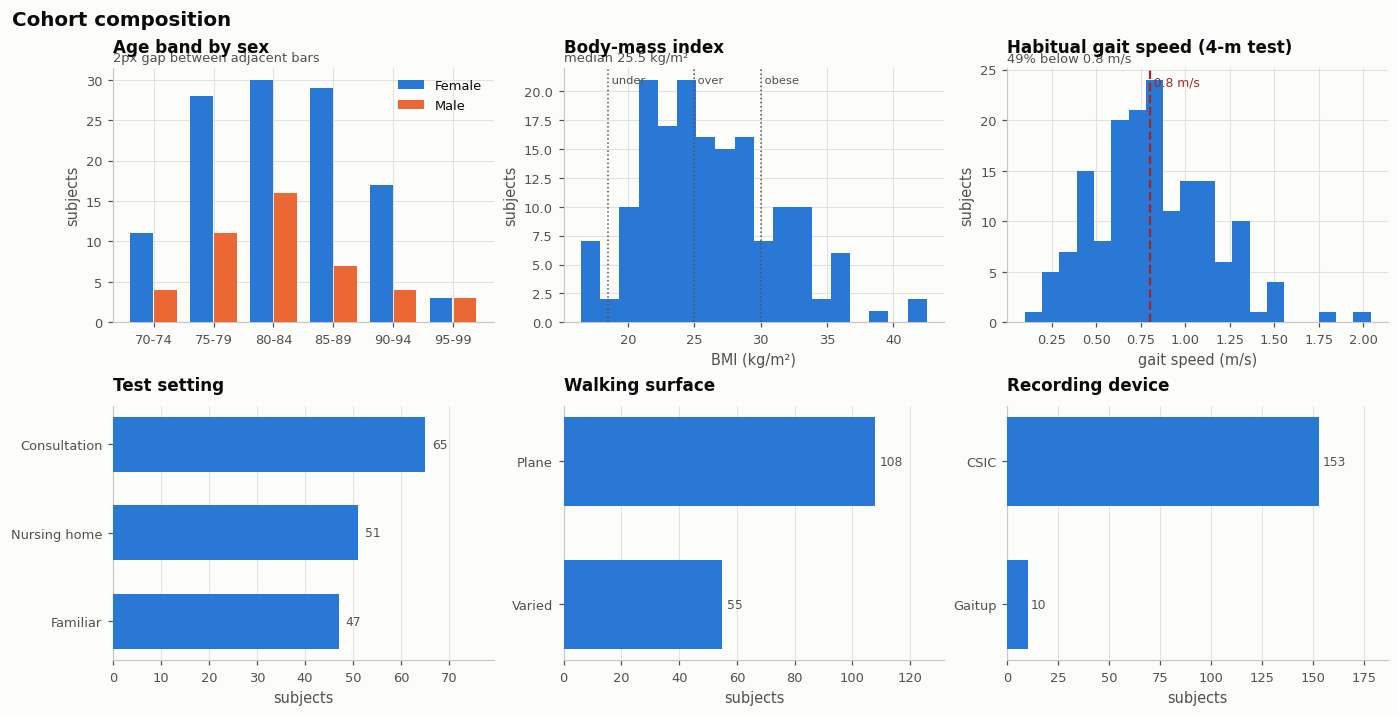

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(12.6, 6.4))

# --- age bands x sex: ordered category on x, 2 series -> legend + fixed slots
ax = axes[0, 0]
bands = sorted(reg["age_band"].unique())
ct = pd.crosstab(reg["age_band"], reg["sex"]).reindex(bands).fillna(0)
x = np.arange(len(bands)); w = 0.38
for i, s in enumerate(["F", "M"]):
    ax.bar(x + (i - .5) * (w + 0.02), ct[s], w, color=CAT[i],
           label={"F": "Female", "M": "Male"}[s], zorder=3)
ax.set_xticks(x); ax.set_xticklabels(bands, rotation=0)
ax.legend(loc="upper right")
finish(ax, "Age band by sex", "2px gap between adjacent bars", None, "subjects")

# --- BMI: single series, no legend needed (title names it)
ax = axes[0, 1]
ax.hist(reg["bmi"].dropna(), bins=18, color=CAT[0], zorder=3)
for v, lab, c in [(18.5, "under", "#52514e"), (25, "over", "#52514e"), (30, "obese", "#52514e")]:
    ax.axvline(v, color=c, lw=1, ls=":", zorder=4)
    ax.text(v, ax.get_ylim()[1] * .97, " " + lab, fontsize=7.5, color=INK_2, va="top")
finish(ax, "Body-mass index", f"median {reg['bmi'].median():.1f} kg/m²", "BMI (kg/m²)", "subjects")

# --- 4-m gait speed with the 0.8 m/s frailty-relevant threshold
ax = axes[0, 2]
ax.hist(reg["gait_speed_4m"].dropna(), bins=20, color=CAT[0], zorder=3)
ax.axvline(0.8, color="#a62625", lw=1.5, ls="--", zorder=4)
ax.text(0.8, ax.get_ylim()[1] * .97, " 0.8 m/s", fontsize=8, color="#a62625", va="top")
finish(ax, "Habitual gait speed (4-m test)",
       f"{100*(reg['gait_speed_4m'] < 0.8).mean():.0f}% below 0.8 m/s",
       "gait speed (m/s)", "subjects")

# --- setting / surface / device: horizontal bars, one series each, direct-labelled
for ax, col, title in [(axes[1, 0], "location", "Test setting"),
                       (axes[1, 1], "surface",  "Walking surface"),
                       (axes[1, 2], "device",   "Recording device")]:
    vc = reg[col].value_counts().sort_values()
    b = ax.barh(np.arange(len(vc)), vc.values, 0.62, color=CAT[0], zorder=3)
    ax.set_yticks(np.arange(len(vc))); ax.set_yticklabels(vc.index)
    ax.set_xlim(0, vc.max() * 1.22); ax.grid(axis="y", visible=False)
    barlabel(ax, b, "{:.0f}", pad=1.5, horiz=True)
    finish(ax, title, None, "subjects", None)

fig.suptitle("Cohort composition", x=0.004, ha="left", fontsize=13,
             fontweight="semibold", color=INK)
plt.show()

The cohort is old (median band 80–84, 26% aged 85+), predominantly female (72%), and functionally heterogeneous: habitual gait speed spans the whole clinically meaningful range and a large fraction sits below the 0.8 m/s mark often used as a slow-gait criterion. That spread is what gives the study any chance of detecting an endurance gradient.

Two design imbalances to carry forward:

- **Device is confounded with setting** — the 10 `Gaitup` recordings come only from
  nursing-home and familiar settings, never from consultations, and they sample at
  128 Hz rather than 104 Hz.
- **Surface varies** (`Plane` indoors vs `Varied` outdoors), and surface plausibly
  affects within-walk speed variability directly.

Neither can be adjusted away cleanly at n = 163; both belong in a sensitivity analysis.

---
## 4. Clinical and self-report measures

The study's **outcomes** and **comparators** both live here.

| Role | Measure | Range / coding |
|---|---|---|
| **Outcome — self-reported endurance** | `fr_low_energy` ("low energy and resistance", ≥2 days/week) | YES / NO |
| **Outcome — overall frailty** | `frailty` (Fried-style count of 5 criteria) | 0 (robust) – 5 |
| Secondary outcome | `falls_1y`, `fesi` (Short FES-I, fear of falling) | YES/NO; 7–28 |
| **Comparator** | `gait_speed_4m` | m/s |
| **Comparator** | `tug_s` (Timed Up and Go) | s |
| **Comparator** | `sppb` (balance + gait + chair stand) | 0–12 |
| **Comparator** | `walk_time_s` (duration of the sustained walk) | s |
| Context | `gds` (Global Deterioration Scale) | 1–7 |

Note `fr_low_energy` is simultaneously the **primary outcome** and **one of the five
components** of the `frailty` index. The two outcomes are therefore not independent —
§12 reports them separately and never treats agreement between them as corroboration.

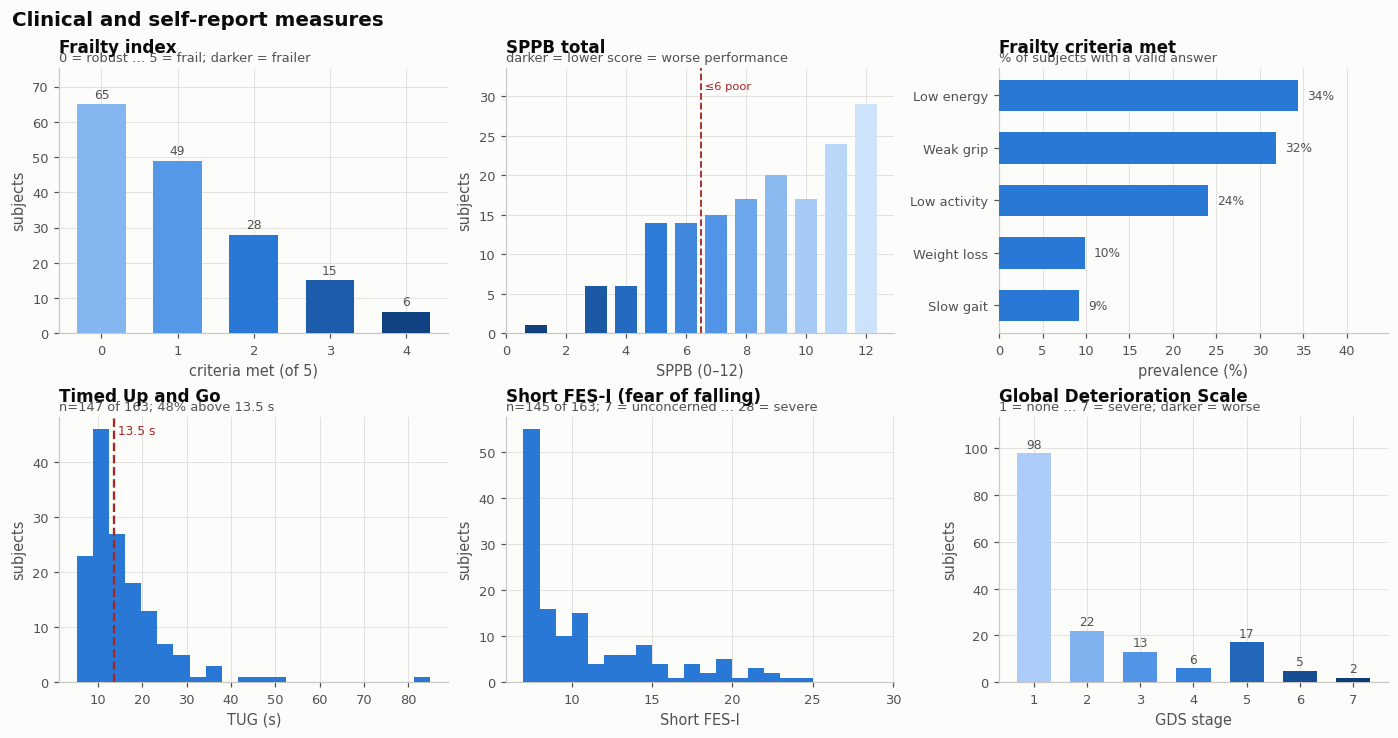

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12.6, 6.6))

# --- frailty: ORDERED category -> single-hue ordinal ramp, not categorical hues
ax = axes[0, 0]
fc = reg["frailty"].value_counts().sort_index()
b = ax.bar(fc.index, fc.values, 0.64, color=[ORDINAL[min(int(i), 4)] for i in fc.index], zorder=3)
barlabel(ax, b, "{:.0f}", pad=1)
ax.set_xticks(range(0, 5)); ax.set_ylim(0, fc.max() * 1.16)
finish(ax, "Frailty index", "0 = robust … 5 = frail; darker = frailer",
       "criteria met (of 5)", "subjects")

# --- SPPB: ordered score, sequential ramp over its own range
ax = axes[0, 1]
sc = reg["sppb"].value_counts().sort_index()
norm = mpl.colors.Normalize(0, 12)
b = ax.bar(sc.index, sc.values, 0.74,
           color=[SEQ_CMAP(1 - norm(i)) for i in sc.index], zorder=3)
ax.set_xticks(range(0, 13, 2)); ax.set_ylim(0, sc.max() * 1.16)
ax.axvline(6.5, color="#a62625", lw=1.2, ls="--", zorder=4)
ax.text(6.5, sc.max() * 1.1, " ≤6 poor", fontsize=7.5, color="#a62625", va="top")
finish(ax, "SPPB total", "darker = lower score = worse performance", "SPPB (0–12)", "subjects")

# --- frailty criteria prevalence: one series, direct-labelled, NaN count shown
ax = axes[0, 2]
crit = {"Weight loss": "fr_weight_loss", "Low energy": "fr_low_energy",
        "Slow gait": "fr_slow_gait", "Weak grip": "fr_weak_grip",
        "Low activity": "fr_low_activity"}
prev = pd.Series({k: 100 * reg[v].mean() for k, v in crit.items()}).sort_values()
b = ax.barh(np.arange(len(prev)), prev.values, 0.6, color=CAT[0], zorder=3)
ax.set_yticks(np.arange(len(prev))); ax.set_yticklabels(prev.index)
ax.set_xlim(0, max(prev) * 1.3); ax.grid(axis="y", visible=False)
barlabel(ax, b, "{:.0f}%", pad=1, horiz=True)
finish(ax, "Frailty criteria met", "% of subjects with a valid answer", "prevalence (%)", None)

# --- TUG
ax = axes[1, 0]
t = reg["tug_s"].dropna()
ax.hist(t, bins=22, color=CAT[0], zorder=3)
ax.axvline(13.5, color="#a62625", lw=1.5, ls="--", zorder=4)
ax.text(13.5, ax.get_ylim()[1] * .97, " 13.5 s", fontsize=8, color="#a62625", va="top")
finish(ax, "Timed Up and Go", f"n={len(t)} of {n}; {100*(t>13.5).mean():.0f}% above 13.5 s",
       "TUG (s)", "subjects")

# --- Short FES-I
ax = axes[1, 1]
f = reg["fesi"].dropna()
ax.hist(f, bins=range(7, 30), color=CAT[0], zorder=3)
finish(ax, "Short FES-I (fear of falling)",
       f"n={len(f)} of {n}; 7 = unconcerned … 28 = severe", "Short FES-I", "subjects")

# --- GDS
ax = axes[1, 2]
g = reg["gds"].value_counts().sort_index()
b = ax.bar(g.index, g.values, 0.64,
           color=[SEQ_CMAP(0.15 + 0.8 * (i - 1) / 6) for i in g.index], zorder=3)
barlabel(ax, b, "{:.0f}", pad=1)
ax.set_xticks(range(1, 8)); ax.set_ylim(0, g.max() * 1.16)
finish(ax, "Global Deterioration Scale", "1 = none … 7 = severe; darker = worse",
       "GDS stage", "subjects")

fig.suptitle("Clinical and self-report measures", x=0.004, ha="left", fontsize=13,
             fontweight="semibold", color=INK)
plt.show()

### Informative missingness, a finding, not a nuisance

`"Incapable"` appears where a volunteer could not complete or could not answer a test.
Dropping those rows silently would be a mistake if they are not missing at random.

In [12]:
mi = pd.DataFrame({
    "n 'Incapable'": incapable.sum(),
    "% of cohort":   (100 * incapable.mean()).round(1),
}).query("`n 'Incapable'` > 0").sort_values("n 'Incapable'", ascending=False)
print("Where 'Incapable' occurs:")
display(mi)

flagged = incapable.any(axis=1)
le_missing = incapable["fr_low_energy"]

comp = pd.DataFrame({
    "answered low-energy item": reg.loc[~le_missing, ["gds", "sppb", "frailty",
                                                      "gait_speed_4m", "walk_time_s"]].median(),
    "'Incapable' on that item": reg.loc[le_missing.values, ["gds", "sppb", "frailty",
                                                            "gait_speed_4m", "walk_time_s"]].median(),
})
comp.index = ["GDS (cognition)", "SPPB", "frailty index", "4-m gait speed (m/s)", "walk duration (s)"]
print(f"\nMedian profile: {int((~le_missing).sum())} answered vs "
      f"{int(le_missing.sum())} 'Incapable' on the low-energy item")
display(comp)

print("GDS stage of the subjects who could not answer the low-energy item:")
print(reg.loc[le_missing.values, "gds"].value_counts().sort_index().to_string())
u, pu = stats.mannwhitneyu(reg.loc[le_missing.values, "gds"], reg.loc[~le_missing.values, "gds"])
print(f"\nGDS, Incapable vs answered: Mann-Whitney U p = {pu:.2g}")

Where 'Incapable' occurs:


,n 'Incapable',% of cohort
fesi,16,9.800
tug_s,15,9.200
fr_low_energy,9,5.500
grip_kg,1,0.600
sppb_chair,1,0.600
sppb_balance,1,0.600
fr_weight_loss,1,0.600
fr_low_activity,1,0.600



Median profile: 154 answered vs 9 'Incapable' on the low-energy item


,answered low-energy item,'Incapable' on that item
GDS (cognition),1.000,5.000
SPPB,9.000,7.000
frailty index,1.000,1.000
4-m gait speed (m/s),0.815,0.560
walk duration (s),"1,276.135","1,384.570"


GDS stage of the subjects who could not answer the low-energy item:
gds
2    1
5    5
6    3

GDS, Incapable vs answered: Mann-Whitney U p = 1.3e-06


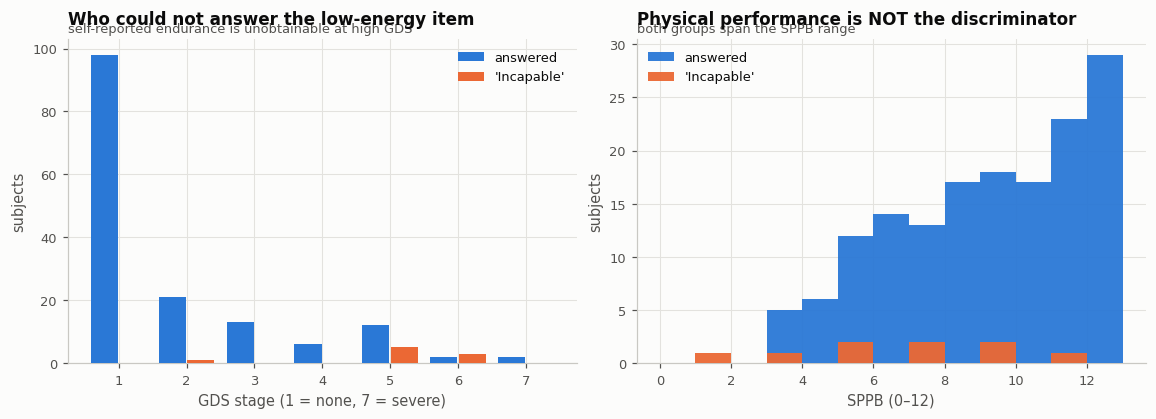

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.7))

ax = axes[0]
ctab = pd.crosstab(reg["gds"], le_missing.values).reindex(range(1, 8)).fillna(0)
x = np.arange(1, 8); w = 0.4
b1 = ax.bar(x - w/2 - 0.01, ctab.get(False, pd.Series(0, index=x)), w,
            color=CAT[0], label="answered", zorder=3)
b2 = ax.bar(x + w/2 + 0.01, ctab.get(True, pd.Series(0, index=x)), w,
            color=CAT[1], label="'Incapable'", zorder=3)
ax.set_xticks(x); ax.legend(loc="upper right")
finish(ax, "Who could not answer the low-energy item",
       "self-reported endurance is unobtainable at high GDS", "GDS stage (1 = none, 7 = severe)",
       "subjects")

ax = axes[1]
ax.hist(reg.loc[~le_missing.values, "sppb"], bins=range(0, 14), color=CAT[0],
        alpha=0.95, label="answered", zorder=3)
ax.hist(reg.loc[le_missing.values, "sppb"], bins=range(0, 14), color=CAT[1],
        alpha=0.95, label="'Incapable'", zorder=4)
ax.legend(loc="upper left")
finish(ax, "Physical performance is NOT the discriminator",
       "both groups span the SPPB range", "SPPB (0–12)", "subjects")
plt.show()

> **Finding.** The 9 subjects who could not answer the self-reported endurance item
> are selected almost entirely by **cognition, not physical capacity**: 8 of 9 sit at
> GDS ≥ 5, while their SPPB and gait speed overlap the rest of the cohort.
>
> Two consequences for the study:
>
> 1. **The primary outcome is missing non-randomly.** Analyses of `fr_low_energy` run
>    on n = 154, and the excluded 9 are the cognitively impaired, so the estimate
>    generalises to cognitively intact older adults only.
> 2. **This strengthens the study's rationale.** Self-reported endurance is
>    *unobtainable* in exactly the subgroup where an objective, sensor-derived
>    endurance measure would be most valuable. A gait-derived measure is available for
>    all 163 subjects, including all 9. That is an argument for the measure
>    independent of how well it correlates with self-report.

---
## 5. The long walk, as summarised by the authors

The register already carries per-subject summaries of the sustained walk (mean and SD
of each gait parameter). These are useful for cross-checking our own pipeline in §8,
but they are **whole-walk averages** and therefore carry no information about *decline*
— which is precisely the quantity this study needs. That is why §6 onward works from
the per-stride files.

In [14]:
reg_sum = [c for c in reg.columns if c.startswith("reg_")]
walk = reg[["walk_time_s", "walk_distance_m", "walk_strides"] + reg_sum]
print(f"{len(reg_sum)} author-supplied summary columns (Avg./STD pairs):")
print(textwrap.fill(", ".join(reg_sum), 150), "\n")
display(walk[["walk_time_s", "walk_distance_m", "walk_strides",
              "reg_stride_time_avg", "reg_cadence_avg", "reg_step_speed_avg",
              "reg_stride_length_avg", "reg_clearance_avg"]]
        .describe().T[["count", "mean", "std", "min", "50%", "max"]])

26 author-supplied summary columns (Avg./STD pairs):
reg_stride_time_avg, reg_stride_time_std, reg_load_avg, reg_load_std, reg_foot_flat_avg, reg_foot_flat_std, reg_push_avg, reg_push_std, reg_swing_avg,
reg_swing_std, reg_toe_off_angle_avg, reg_toe_off_angle_std, reg_heel_strike_angle_avg, reg_heel_strike_angle_std, reg_cadence_avg, reg_cadence_std,
reg_step_speed_avg, reg_step_speed_std, reg_stride_length_avg, reg_stride_length_std, reg_3d_path_avg, reg_3d_path_std, reg_2d_path_avg,
reg_2d_path_std, reg_clearance_avg, reg_clearance_std 



,count,mean,std,min,50%,max
walk_time_s,163.000,"1,281.585",424.236,338.600,"1,290.550","2,184.400"
walk_distance_m,163.000,"1,006.465",610.353,73.016,903.934,"2,684.817"
walk_strides,163.000,"1,082.638",413.645,213.000,"1,064.000","2,185.000"
reg_stride_time_avg,163.000,1.256,0.245,0.900,1.205,2.488
reg_cadence_avg,163.000,49.203,7.544,24.010,49.840,66.370
reg_step_speed_avg,163.000,0.833,0.314,0.120,0.790,1.607
reg_stride_length_avg,163.000,0.912,0.264,0.291,0.892,1.530
reg_clearance_avg,163.000,0.170,0.138,0.024,0.122,0.664


---
## 6. Per-stride metrics files

These are the analysis input. One file per subject, one **row per stride**, produced by
the authors' ZUPT pipeline.

The header is whitespace-delimited but **column names contain spaces and are quoted**,
so `sep=r"\s+"` shreds the header into 41 fragments. The loader below parses the header
with `shlex` and the body with the fast C engine.

There is **no timestamp column** — elapsed time has to be reconstructed as the
cumulative sum of `Stride time (s)`. That reconstruction is what makes a within-walk
slope possible at all, and it is also where the pauses hide (§6.2).

In [15]:
STRIDE_COLS = ["Stride time (s)", "Swing (% gait cycle)", "Toe Off (% gait cycle)",
               "Heel Strike (% gait cycle)", "Foot Flat (% gait cycle)",
               "Toe off angle (°)", "Heel Strike angle (°)", "Cadence (strides/min)",
               "Speed (m/s)", "Stride Length (m)", "Clearance (m)"]

def load_strides(subject_id):
    # One subject's per-stride table, with elapsed time reconstructed.
    path = DIR_METRICS / f"{subject_id}_metrics.txt"
    with open(path, encoding="utf-8") as f:
        header = shlex.split(f.readline())          # quoted names with spaces
    d = pd.read_csv(path, sep=r"\s+", skiprows=1, header=None, names=header, engine="c")
    d["t_end_s"] = d["Stride time (s)"].cumsum()    # elapsed wall-clock, INCLUDING pauses
    d["t_min"]   = d["t_end_s"] / 60.0
    d["subject"] = subject_id
    return d

print("Raw first line of V001_metrics.txt (note the quoting):")
print("  ", (DIR_METRICS / "V001_metrics.txt").read_text().splitlines()[0])

demo = load_strides("V001")
print(f"\nparsed columns ({len(demo.columns)}):")
for c in demo.columns: print("   ", c)
print(f"\nshape: {demo.shape}")
display(demo.head(4))
display(demo[STRIDE_COLS].describe(percentiles=[.01, .5, .99]).T)

Raw first line of V001_metrics.txt (note the quoting):
   "Num. Step" "Stride time (s)" "Swing (% gait cycle)" "Toe Off (% gait cycle)" "Heel Strike (% gait cycle)" "Foot Flat (% gait cycle)" "Toe off angle (°)" "Heel Strike angle (°)" "Cadence (strides/min)" "Speed (m/s)" "Stride Length (m)" "Clearance (m)"

parsed columns (15):
    Num. Step
    Stride time (s)
    Swing (% gait cycle)
    Toe Off (% gait cycle)
    Heel Strike (% gait cycle)
    Foot Flat (% gait cycle)
    Toe off angle (°)
    Heel Strike angle (°)
    Cadence (strides/min)
    Speed (m/s)
    Stride Length (m)
    Clearance (m)
    t_end_s
    t_min
    subject

shape: (1688, 15)


,Num. Step,Stride time (s),Swing (% gait cycle),Toe Off (% gait cycle),Heel Strike (% gait cycle),Foot Flat (% gait cycle),Toe off angle (°),Heel Strike angle (°),Cadence (strides/min),Speed (m/s),Stride Length (m),Clearance (m),t_end_s,t_min,subject
0,0,1.884,19.797,47.716,10.660,21.827,-47.989,23.237,31.853,0.614,1.030,0.077,1.884,0.031,V001
1,1,1.425,32.886,16.107,24.832,26.174,-70.563,13.528,42.114,0.865,1.117,0.141,3.309,0.055,V001
2,2,1.100,33.043,20.000,20.870,26.087,-51.327,20.872,54.565,1.029,1.052,0.173,4.409,0.073,V001
3,3,1.367,26.573,27.972,12.587,32.867,-74.607,18.208,43.881,0.994,1.297,0.172,5.776,0.096,V001


,count,mean,std,min,1%,50%,99%,max
Stride time (s),"1,688.000",1.023,0.081,0.698,0.793,1.023,1.206,2.190
Swing (% gait cycle),"1,688.000",31.939,1.872,14.847,27.642,31.818,38.824,55.682
Toe Off (% gait cycle),"1,688.000",19.747,2.454,7.860,16.504,19.417,30.474,47.716
Heel Strike (% gait cycle),"1,688.000",12.821,1.825,1.136,9.091,12.727,17.459,36.190
Foot Flat (% gait cycle),"1,688.000",35.492,3.290,14.286,20.963,35.806,40.777,70.742
Toe off angle (°),"1,688.000",-71.620,4.932,-91.230,-81.054,-72.150,-54.458,-37.913
Heel Strike angle (°),"1,688.000",27.345,4.315,0.000,13.836,28.017,34.740,46.000
Cadence (strides/min),"1,688.000",58.989,4.468,27.401,49.750,58.644,75.722,85.958
Speed (m/s),"1,688.000",1.352,0.122,0.426,1.070,1.345,1.730,1.932
Stride Length (m),"1,688.000",1.213,0.093,0.811,0.936,1.227,1.378,1.448


### 6.1 The gait cycle as decomposed here

The four phase columns are percentages of the gait cycle and should roughly sum to
100%. Confirming that tells us the phase detector is internally consistent.

In [16]:
PHASES = ["Heel Strike (% gait cycle)", "Foot Flat (% gait cycle)",
          "Toe Off (% gait cycle)", "Swing (% gait cycle)"]
tot = demo[PHASES].sum(axis=1)
print(f"V001 phase percentages sum to: mean {tot.mean():.2f}%, "
      f"sd {tot.std():.3f}%, range [{tot.min():.1f}, {tot.max():.1f}]")

# The register uses different names for the same phases - map them.
print("\nRegister naming vs per-stride naming (V001, whole-walk mean):")
display(pd.DataFrame({
    "per-stride mean": [demo[p].mean() for p in PHASES],
    "register value":  [reg.loc["V001", c] for c in
                        ["reg_load_avg", "reg_foot_flat_avg", "reg_push_avg", "reg_swing_avg"]],
}, index=["Heel Strike  ≙ 'Load'", "Foot Flat  ≙ 'Foot Flat'",
          "Toe Off  ≙ 'Push'",    "Swing  ≙ 'Swing'"]))

V001 phase percentages sum to: mean 100.00%, sd 0.001%, range [100.0, 100.0]

Register naming vs per-stride naming (V001, whole-walk mean):


,per-stride mean,register value
Heel Strike ≙ 'Load',12.821,12.780
Foot Flat ≙ 'Foot Flat',35.492,35.540
Toe Off ≙ 'Push',19.747,19.520
Swing ≙ 'Swing',31.939,31.940


### 6.2 What a single walk actually looks like

This is the most important diagnostic plot in the notebook. It shows why the raw
per-stride series cannot be fed to a regression as-is.

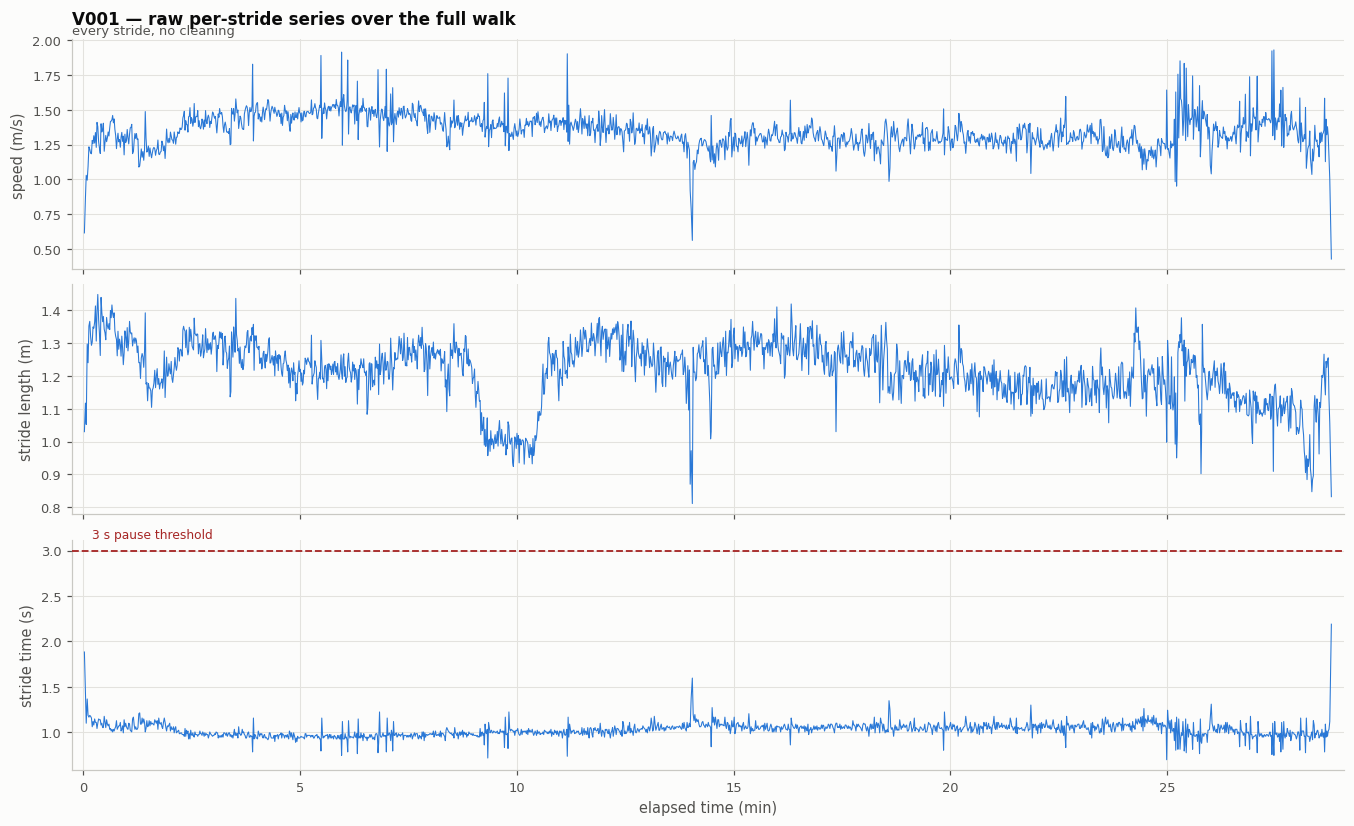

V001: 1688 strides over 28.8 min
  longest single 'stride': 2.2 s (median 1.02 s)
  strides with stride time > 3 s: 0
  strides with stride length > 2 m: 0


In [17]:
fig, axes = plt.subplots(3, 1, figsize=(12.2, 7.4), sharex=True)
d = demo

ax = axes[0]
ax.plot(d["t_min"], d["Speed (m/s)"], lw=0.7, color=CAT[0])
finish(ax, "V001 — raw per-stride series over the full walk",
       "every stride, no cleaning", None, "speed (m/s)")

ax = axes[1]
ax.plot(d["t_min"], d["Stride Length (m)"], lw=0.7, color=CAT[0])
finish(ax, None, None, None, "stride length (m)")

ax = axes[2]
ax.plot(d["t_min"], d["Stride time (s)"], lw=0.7, color=CAT[0])
ax.axhline(3.0, color="#a62625", lw=1.2, ls="--", zorder=4)
ax.text(0.2, 3.1, "3 s pause threshold", fontsize=8, color="#a62625", va="bottom")
finish(ax, None, None, "elapsed time (min)", "stride time (s)")

for ax in axes:
    ax.margins(x=0.01)
plt.show()

print(f"V001: {len(d)} strides over {d['t_min'].iloc[-1]:.1f} min")
print(f"  longest single 'stride': {d['Stride time (s)'].max():.1f} s "
      f"(median {d['Stride time (s)'].median():.2f} s)")
print(f"  strides with stride time > 3 s: {(d['Stride time (s)'] > 3).sum()}")
print(f"  strides with stride length > 2 m: {(d['Stride Length (m)'] > 2).sum()}")

Two artefact families are visible, and they have different causes:

1. **Pauses masquerade as single enormous strides.** When the volunteer stops, the
   step detector sees one flat-foot phase lasting seconds to minutes and emits a
   single "stride" with a huge `Stride time`. Across the cohort the longest such
   pseudo-stride reaches **545 s** (9 minutes). Left in place, these distort elapsed
   time, dominate any mean, and anchor a regression.
2. **ZUPT failures produce impossible spatial values.** Occasional strides report
   lengths of tens or even thousands of metres, where the velocity integration failed
   to reset. These are rare but extreme.